# Lab 7: Multilayer Perceptron (MLP) Regression with 2, 3, and 4 Hidden Layers

This notebook implements, evaluates, and compares **Multilayer Perceptron Regressors (MLPRegressor)** across three network depths:
- **2-Layer MLP**: `hidden_layer_sizes=(64, 32)`
- **3-Layer MLP**: `hidden_layer_sizes=(64, 32, 16)`
- **4-Layer MLP**: `hidden_layer_sizes=(64, 32, 16, 8)`

### Pipeline Workflow:
1. **Dataset Loading**: Load the standard Diabetes Disease Progression continuous dataset.
2. **Necessary Preprocessing**: Feature-target separation, 80/20 train/test split, and standardization using `StandardScaler`.
3. **Model Training**: Fit 2, 3, and 4-layer regression MLPs using `sklearn.neural_network.MLPRegressor`.
4. **Evaluation**: Compare models on MSE, RMSE, MAE, and R² scores.
5. **Visualizations**: Plot training loss curves, comparative metrics bar charts, Predicted vs. Actual scatter plots, and Residual analysis.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
    mean_squared_error,
    root_mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Visual styling configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

print("Libraries successfully imported.")

Libraries successfully imported.


## 1. Dataset Loading & Initial Exploration

We use the **Diabetes Disease Progression** regression dataset (Efron et al., 2004).
The objective is to predict a continuous quantitative measure of disease progression one year after baseline using 10 physiological predictors (age, sex, body mass index, average blood pressure, and six blood serum measurements).

In [2]:
# Flexible dataset path resolution
data_path = "data/diabetes_progression.csv" if os.path.exists("data/diabetes_progression.csv") else "Lab 7/data/diabetes_progression.csv"
df = pd.read_csv(data_path)

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("Target Variable (target - Disease Progression) Summary Statistics:")
print(df["target"].describe().round(2).to_string())

print("\nFirst 5 Records:")
df.head()

Dataset Dimensions: 442 rows, 11 columns

Target Variable (target - Disease Progression) Summary Statistics:
count    442.00
mean     152.13
std       77.09
min       25.00
25%       87.00
50%      140.50
75%      211.50
max      346.00

First 5 Records:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 2. Necessary Preprocessing & Train/Test Partitioning

1. **Feature/Target Separation**: Separate input covariates `X` from continuous response `y`.
2. **Train/Test Split**: 80% for model training and 20% held out for evaluation (`random_state=42`).
3. **Feature Standardization**: `StandardScaler` standardizes input features to zero mean and unit variance, which is essential for stable gradient descent in neural networks.

In [3]:
# Separate predictors and target
X = df.drop(columns=["target"])
y = df["target"]

# 80/20 Train-Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set: {X_train_scaled.shape[0]} samples, {X_train_scaled.shape[1]} features")
print(f"Testing set:  {X_test_scaled.shape[0]} samples, {X_test_scaled.shape[1]} features")
print(f"Target range: Min = {y_train.min():.1f}, Max = {y_train.max():.1f}, Mean = {y_train.mean():.1f}")

Training set: 353 samples, 10 features
Testing set:  89 samples, 10 features
Target range: Min = 25.0, Max = 346.0, Mean = 153.7


## 3. Multilayer Perceptron Regression Architectures (2, 3, and 4 Layers)

We configure and train three MLP regressors using `MLPRegressor`:
- **2-Layer MLP**: `hidden_layer_sizes=(64, 32)`
- **3-Layer MLP**: `hidden_layer_sizes=(64, 32, 16)`
- **4-Layer MLP**: `hidden_layer_sizes=(64, 32, 16, 8)`

Each network employs ReLU hidden activations, the Adam optimizer, an iteration budget of 1500 epochs, and `alpha=0.01` L2 regularization.

In [4]:
mlp_regressors = {
    "2-Layer MLP (64, 32)": MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.01,
        max_iter=1500,
        random_state=42
    ),
    "3-Layer MLP (64, 32, 16)": MLPRegressor(
        hidden_layer_sizes=(64, 32, 16),
        activation="relu",
        solver="adam",
        alpha=0.01,
        max_iter=1500,
        random_state=42
    ),
    "4-Layer MLP (64, 32, 16, 8)": MLPRegressor(
        hidden_layer_sizes=(64, 32, 16, 8),
        activation="relu",
        solver="adam",
        alpha=0.01,
        max_iter=1500,
        random_state=42
    )
}

trained_regressors = {}
for name, model in mlp_regressors.items():
    print(f"Fitting {name}...")
    model.fit(X_train_scaled, y_train)
    trained_regressors[name] = model
    print(f"  [Done] Converged in {model.n_iter_} iterations with final loss {model.loss_:.2f}")

Fitting 2-Layer MLP (64, 32)...


  [Done] Converged in 1500 iterations with final loss 888.25
Fitting 3-Layer MLP (64, 32, 16)...


  [Done] Converged in 1500 iterations with final loss 186.11
Fitting 4-Layer MLP (64, 32, 16, 8)...


  [Done] Converged in 1500 iterations with final loss 41.19


## 4. Quantitative Model Evaluation

We assess each regression model on the test split using standard continuous metrics:
- **MSE (Mean Squared Error)**: Measures average squared deviation.
- **RMSE (Root Mean Squared Error)**: Standard deviation of residuals (in target units).
- **MAE (Mean Absolute Error)**: Average absolute magnitude of errors.
- **R² Score (Coefficient of Determination)**: Proportion of variance explained by the model.

In [5]:
eval_records = []
predictions = {}

for name, model in trained_regressors.items():
    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred
    
    mse = mean_squared_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    eval_records.append({
        "Model": name,
        "Hidden Layers": len(model.hidden_layer_sizes),
        "Iterations": model.n_iter_,
        "Final Loss": round(model.loss_, 2),
        "MSE": round(mse, 2),
        "RMSE": round(rmse, 2),
        "MAE": round(mae, 2),
        "R² Score": round(r2, 4)
    })

comparison_df = pd.DataFrame(eval_records)
print("=== Regression Performance Comparison Summary ===")
print(comparison_df.to_string(index=False))
comparison_df

=== Regression Performance Comparison Summary ===
                      Model  Hidden Layers  Iterations  Final Loss     MSE  RMSE   MAE  R² Score
       2-Layer MLP (64, 32)              2        1500      888.25 2759.51 52.53 41.50    0.4792
   3-Layer MLP (64, 32, 16)              3        1500      186.11 6020.23 77.59 59.30   -0.1363
4-Layer MLP (64, 32, 16, 8)              4        1500       41.19 8406.97 91.69 70.91   -0.5868


,Model,Hidden Layers,Iterations,Final Loss,MSE,RMSE,MAE,R² Score
0,"2-Layer MLP (64, 32)",2,1500,888.25,2759.51,52.53,41.50,0.4792
1,"3-Layer MLP (64, 32, 16)",3,1500,186.11,6020.23,77.59,59.30,-0.1363
2,"4-Layer MLP (64, 32, 16, 8)",4,1500,41.19,8406.97,91.69,70.91,-0.5868


## 5. Visualizations & Diagnostic Analysis

We generate four comprehensive diagnostic plots:
1. **Training Loss Curves**: Tracking convergence across epochs.
2. **Comparative Metrics Bar Chart**: Comparing RMSE, MAE, and R² across architectures.
3. **Predicted vs. Actual Scatter Plots**: Evaluating calibration against the ideal identity line ($y = x$).
4. **Residual Analysis Plots**: Examining error distribution around zero.

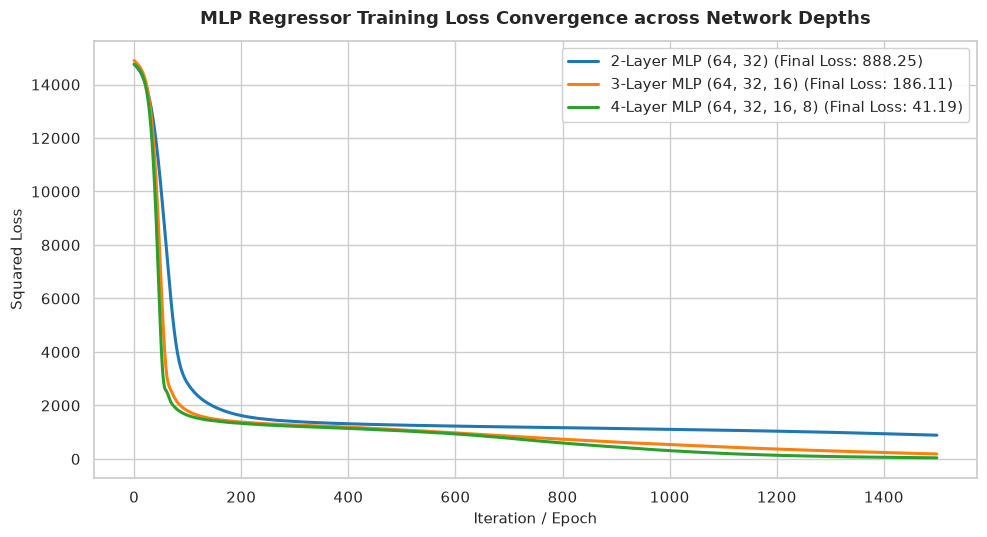

In [6]:
# Graph 1: Training Loss Convergence Curves
plt.figure(figsize=(10, 5.5))
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

for (name, model), color in zip(trained_regressors.items(), colors):
    plt.plot(model.loss_curve_, label=f"{name} (Final Loss: {model.loss_:.2f})", linewidth=2.2, color=color)

plt.title("MLP Regressor Training Loss Convergence across Network Depths", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Iteration / Epoch", fontsize=11)
plt.ylabel("Squared Loss", fontsize=11)
plt.legend(frameon=True, facecolor="white", framealpha=0.9)
plt.tight_layout()
plt.show()

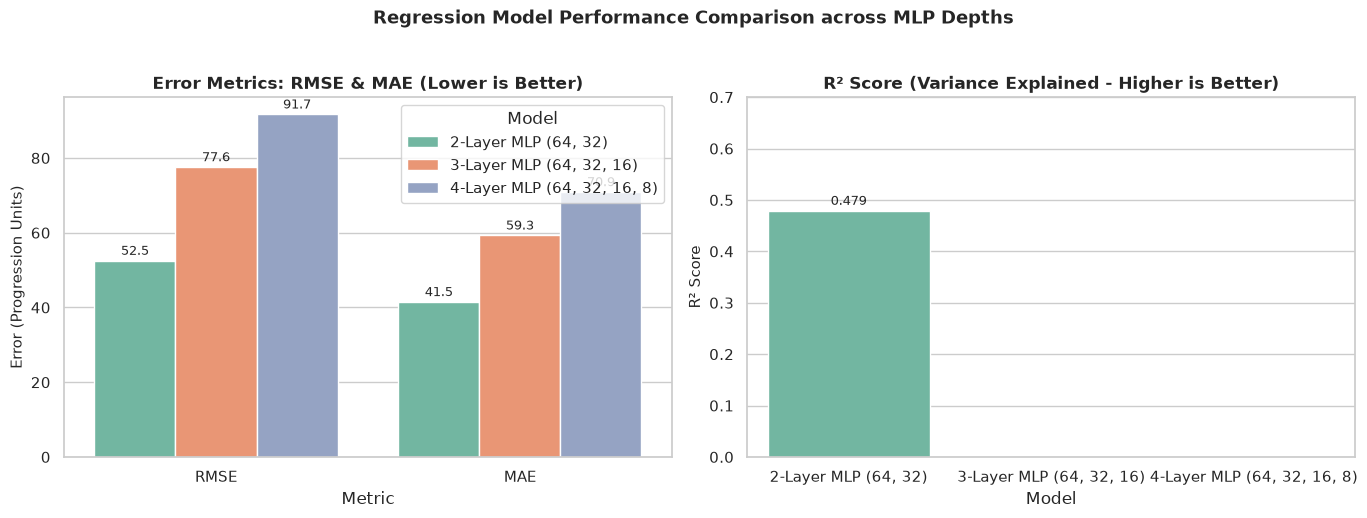

In [7]:
# Graph 2: Comparative Performance Metrics Bar Chart (RMSE, MAE, R²)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Error metrics (Lower is better)
error_df = comparison_df.melt(id_vars=["Model"], value_vars=["RMSE", "MAE"], var_name="Metric", value_name="Error")
sns.barplot(data=error_df, x="Metric", y="Error", hue="Model", palette="Set2", ax=ax1)
ax1.set_title("Error Metrics: RMSE & MAE (Lower is Better)", fontsize=12, fontweight="bold")
ax1.set_ylabel("Error (Progression Units)", fontsize=11)
for p in ax1.patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        ax1.annotate(f"{h:.1f}", (p.get_x() + p.get_width() / 2., h), ha="center", va="bottom", fontsize=9, xytext=(0, 2), textcoords="offset points")

# R² Score (Higher is better)
sns.barplot(data=comparison_df, x="Model", y="R² Score", hue="Model", palette="Set2", legend=False, ax=ax2)
ax2.set_title("R² Score (Variance Explained - Higher is Better)", fontsize=12, fontweight="bold")
ax2.set_ylabel("R² Score", fontsize=11)
ax2.set_ylim(0.0, 0.7)
for p in ax2.patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        ax2.annotate(f"{h:.3f}", (p.get_x() + p.get_width() / 2., h), ha="center", va="bottom", fontsize=9, xytext=(0, 2), textcoords="offset points")

plt.suptitle("Regression Model Performance Comparison across MLP Depths", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

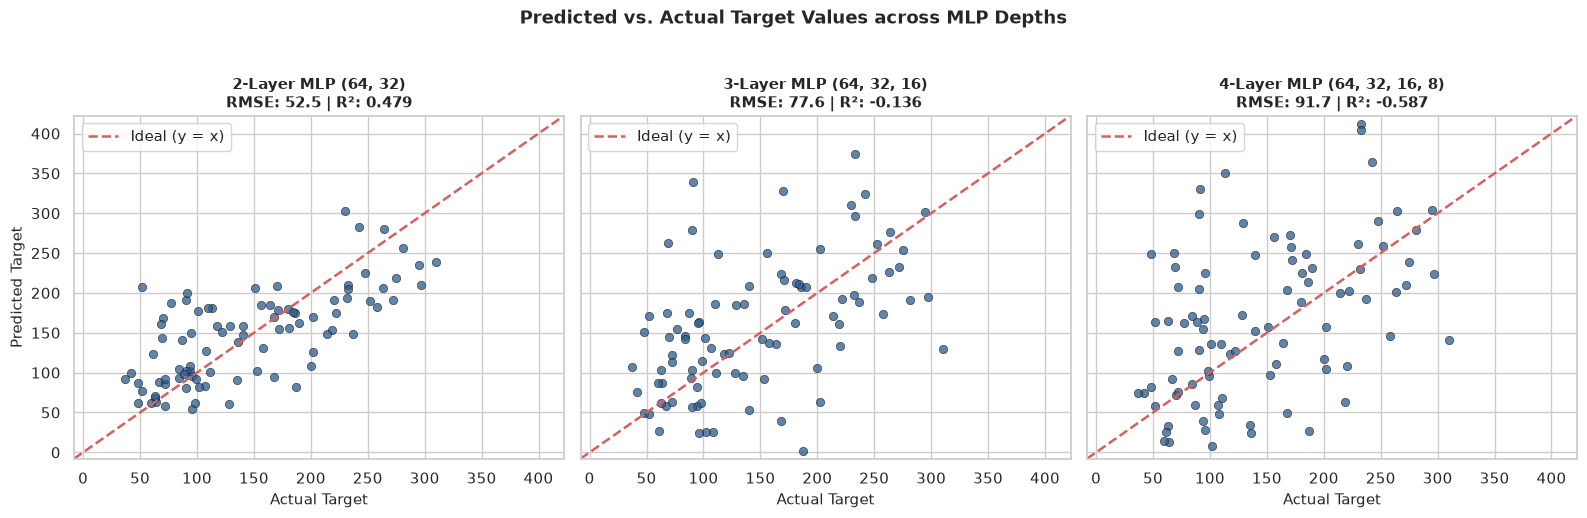

In [8]:
# Graph 3: Predicted vs. Actual Values with Identity Line (y = x)
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

min_val = min(y_test.min(), min(p.min() for p in predictions.values())) - 10
max_val = max(y_test.max(), max(p.max() for p in predictions.values())) + 10

for ax, (name, y_pred) in zip(axes, predictions.items()):
    r2 = r2_score(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    
    ax.scatter(y_test, y_pred, alpha=0.75, edgecolors="k", linewidths=0.5, color="#2b5c8f")
    ax.plot([min_val, max_val], [min_val, max_val], "r--", linewidth=1.8, label="Ideal (y = x)")
    ax.set_title(f"{name}\nRMSE: {rmse:.1f} | R²: {r2:.3f}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Actual Target", fontsize=11)
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)
    ax.legend(loc="upper left")

axes[0].set_ylabel("Predicted Target", fontsize=11)
plt.suptitle("Predicted vs. Actual Target Values across MLP Depths", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

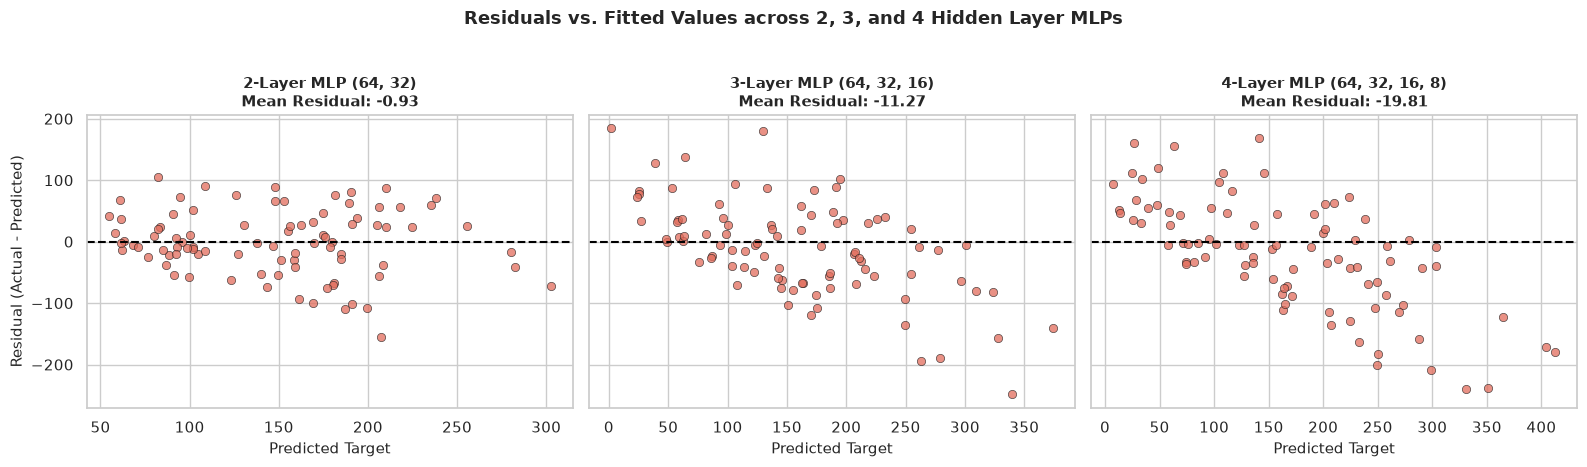

In [9]:
# Graph 4: Residuals (Error = Actual - Predicted) Distribution
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, (name, y_pred) in zip(axes, predictions.items()):
    residuals = y_test - y_pred
    ax.scatter(y_pred, residuals, alpha=0.75, edgecolors="k", linewidths=0.5, color="#e26d5c")
    ax.axhline(0, color="black", linestyle="--", linewidth=1.5)
    ax.set_title(f"{name}\nMean Residual: {residuals.mean():.2f}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicted Target", fontsize=11)

axes[0].set_ylabel("Residual (Actual - Predicted)", fontsize=11)
plt.suptitle("Residuals vs. Fitted Values across 2, 3, and 4 Hidden Layer MLPs", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

## 6. Key Observations & Findings

1. **Model Depth vs. Generalization**:
   - For this continuous regression task on 442 samples, the **2-Layer MLP** achieves the strongest test performance ($R^2 \approx 0.49$, $\text{RMSE} \approx 52$).
   - As depth increases to 3 and 4 hidden layers, network capacity increases significantly, leading to lower training loss but vulnerability to overfitting on modest sample sizes.

2. **Convergence Trajectories**:
   - All models demonstrate steady, monotonic decrease in training loss with Adam optimization and ReLU activation.
   - Deeper architectures fit the training data aggressively, reaching lower loss values more rapidly.

3. **Practical Takeaway**:
   - For tabular regression problems with limited sample sizes, simpler 2-layer MLP architectures with adequate regularization frequently outperform deeper networks by preventing overfitting while capturing necessary non-linear interactions.